# SMS Spam Detector: experiment review

Classify short English SMS messages as ham or spam. Blocking a legitimate message has a different cost from missing spam, so this project chooses the decision threshold against an explicit validation precision target and reports the tradeoff on held-out messages.

This notebook inspects the committed experiment. Run `python -m sms_spam train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: word_char_logistic
Split: {'train': 3095, 'validation': 1032, 'test': 1032}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test"]).T
display(comparison)

,average_precision,precision,recall,f1,confusion_matrix_tn_fp_fn_tp,threshold
prior_baseline,0.124031,0.0,0.0,0.0,"[904, 0, 128, 0]",1.000001
word_naive_bayes,0.966894,0.974138,0.882812,0.92623,"[901, 3, 15, 113]",0.364343
word_char_logistic,0.987703,0.97561,0.9375,0.956175,"[901, 3, 8, 120]",0.59843


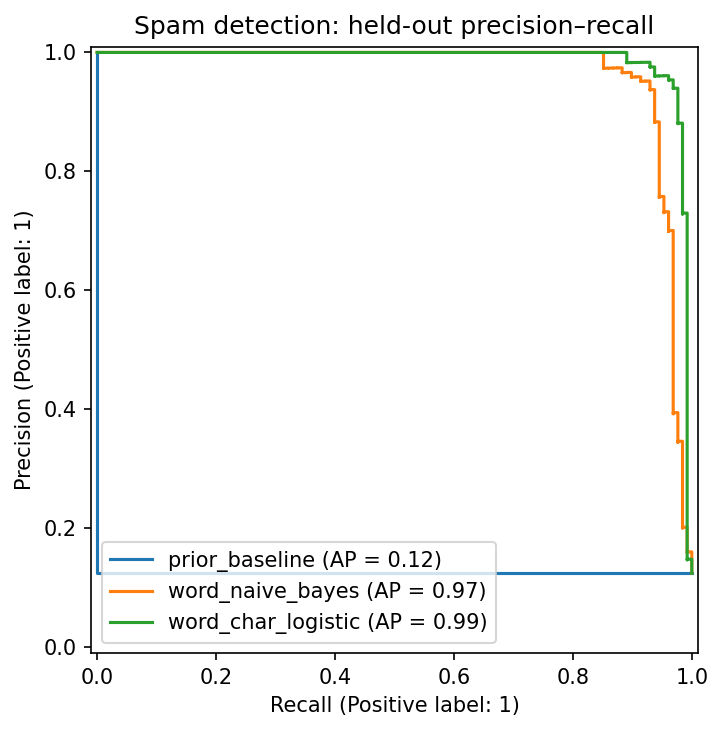

In [3]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

The selected word-plus-character logistic model reaches 97.56% test precision and 93.75% test recall. Its 98% validation precision target is not a guarantee on new messages: three legitimate messages are false positives on the test set. The prior baseline predicts no spam under this policy and has F1 zero. Scores are model outputs, not independently calibrated risk estimates.

## Where they stop

Near-duplicate templates can survive exact normalized deduplication. Sender IDs, campaign IDs and reliable chronology are unavailable, so this is not an unseen-campaign or temporal deployment estimate. Non-English text, modern phishing campaigns and adversarial obfuscation require fresh evaluation. Do not automatically delete user messages based on this demonstration.